# 🔬 ResNet-18 FAF Classifier — Confusion Matrix Analysis

This notebook loads the trained **ResNet-18** model (3 classes: **Choroiditis**, **Normal**, **Scar**) and evaluates it on the **entire dataset** to produce:

- A **Confusion Matrix** heatmap showing True Positives, False Positives, False Negatives, and True Negatives for each class
- A **Classification Report** with Precision, Recall, F1-Score, and Support
- Per-class **accuracy breakdown**

In [1]:
import os
import torch
import torch.nn as nn
import numpy as np
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

print("All imports successful ✅")

All imports successful ✅


In [2]:
# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR   = r"C:\Users\ashut\BE_Project\Dataset\Generated_FAF_CNN_Dataset_Refactored_3classes"
WEIGHTS    = r"C:\Users\ashut\BE_Project\Codes\Training\Training_3_classes\best_resnet_faf_classifier.pth"
BATCH_SIZE = 16

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
# ==========================================
# LOAD THE TRAINED MODEL
# ==========================================

# Class names (must match the folder order used during training)
class_names = sorted(os.listdir(DATA_DIR))
num_classes = len(class_names)
print(f"Classes ({num_classes}): {class_names}")

# Build the same architecture used for training
model = models.resnet18(weights=None)   # no pretrained weights — we load our own
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)

# Load trained weights
model.load_state_dict(torch.load(WEIGHTS, map_location=device))
model = model.to(device)
model.eval()

print("\n✅ Model loaded and set to eval mode!")

Classes (3): ['Choroiditis', 'Normal', 'Scar']


C:\Users\ashut\AppData\Local\Temp\ipykernel_14768\2936689589.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(WEIGHTS, map_location=devi


✅ Model loaded and set to eval mode!


In [4]:
# ==========================================
# TRANSFORMS  (same as validation transforms)
# ==========================================
eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

print("Transforms ready ✅")

Transforms ready ✅


In [5]:
# ==========================================
# LOAD FULL DATASET VIA ImageFolder
# ==========================================
dataset = datasets.ImageFolder(root=DATA_DIR, transform=eval_transforms)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Total images in dataset: {len(dataset)}")
print(f"Class-to-index mapping : {dataset.class_to_idx}")

Total images in dataset: 62
Class-to-index mapping : {'Choroiditis': 0, 'Normal': 1, 'Scar': 2}


In [6]:
# ==========================================
# RUN INFERENCE ON ALL IMAGES
# ==========================================
all_preds  = []
all_labels = []

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

overall_acc = np.mean(all_preds == all_labels) * 100
print(f"\n✅ Inference complete on {len(all_labels)} images")
print(f"Overall Accuracy: {overall_acc:.2f}%")


✅ Inference complete on 62 images
Overall Accuracy: 82.26%


In [7]:
# ==========================================
# COMPUTE CONFUSION MATRIX
# ==========================================
cm = confusion_matrix(all_labels, all_preds)

print("Confusion Matrix (rows = True, cols = Predicted):")
print(cm)
print()

# ---- Per-class TP / FP / FN / TN ----
print(f"{'Class':<15} {'TP':>6} {'FP':>6} {'FN':>6} {'TN':>6}  {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 85)

for idx, cls in enumerate(class_names):
    tp = cm[idx, idx]
    fp = cm[:, idx].sum() - tp
    fn = cm[idx, :].sum() - tp
    tn = cm.sum() - tp - fp - fn
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    print(f"{cls:<15} {tp:>6} {fp:>6} {fn:>6} {tn:>6}  {precision:>10.4f} {recall:>10.4f} {f1:>10.4f}")

Confusion Matrix (rows = True, cols = Predicted):
[[25  0  2]
 [ 4  7  2]
 [ 3  0 19]]

Class               TP     FP     FN     TN   Precision     Recall         F1
-------------------------------------------------------------------------------------
Choroiditis         25      7      2     28      0.7812     0.9259     0.8475
Normal               7      0      6     49      1.0000     0.5385     0.7000
Scar                19      4      3     36      0.8261     0.8636     0.8444


In [8]:
# ==========================================
# SKLEARN CLASSIFICATION REPORT
# ==========================================
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
report = classification_report(all_labels, all_preds, target_names=class_names, digits=4)
print(report)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Choroiditis     0.7812    0.9259    0.8475        27
      Normal     1.0000    0.5385    0.7000        13
        Scar     0.8261    0.8636    0.8444        22

    accuracy                         0.8226        62
   macro avg     0.8691    0.7760    0.7973        62
weighted avg     0.8430    0.8226    0.8155        62



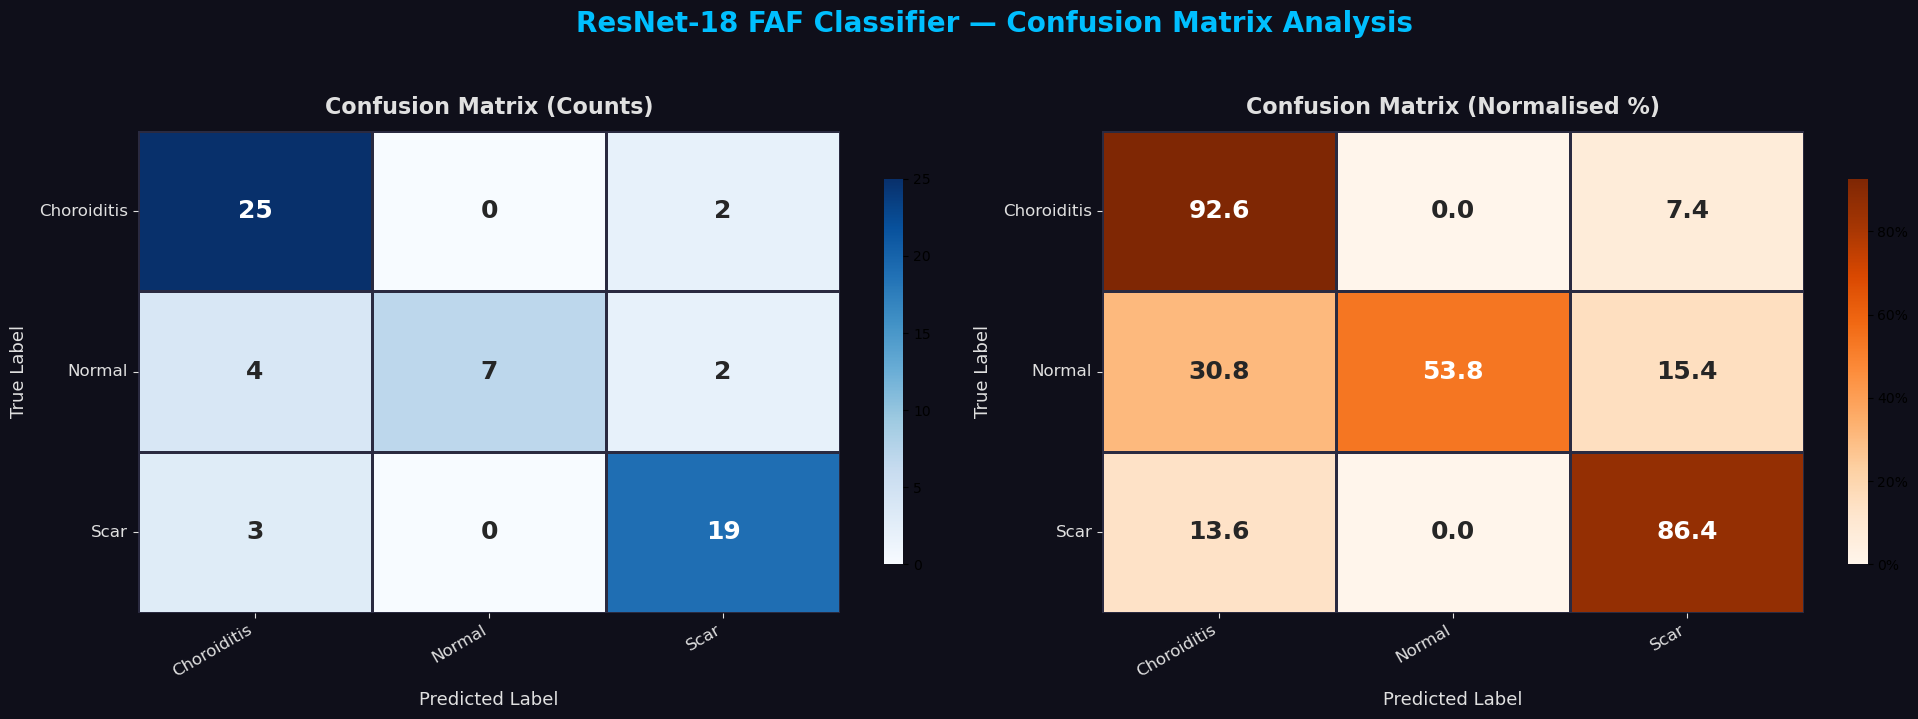


✅ Confusion matrix saved to confusion_matrix_results.png


In [9]:
# ==========================================
# CONFUSION MATRIX HEATMAP VISUALIZATION
# ==========================================

# ---------- colour palette ----------
BG_COLOR    = "#0f0f1a"
TEXT_COLOR  = "#e0e0e0"
ACCENT      = "#00bfff"
GRID_COLOR  = "#2a2a40"

fig, axes = plt.subplots(1, 2, figsize=(20, 7), facecolor=BG_COLOR)

# ---- subplot 1: Raw counts ----
ax1 = axes[0]
ax1.set_facecolor(BG_COLOR)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=2, linecolor=GRID_COLOR,
            annot_kws={"size": 18, "weight": "bold"},
            cbar_kws={"shrink": 0.8},
            ax=ax1)
ax1.set_title("Confusion Matrix (Counts)", fontsize=16, fontweight="bold",
              color=TEXT_COLOR, pad=12)
ax1.set_xlabel("Predicted Label", fontsize=13, color=TEXT_COLOR, labelpad=8)
ax1.set_ylabel("True Label",      fontsize=13, color=TEXT_COLOR, labelpad=8)
ax1.tick_params(colors=TEXT_COLOR, labelsize=12)
plt.setp(ax1.get_xticklabels(), rotation=30, ha='right')
plt.setp(ax1.get_yticklabels(), rotation=0)

# ---- subplot 2: Normalised (%) ----
ax2 = axes[1]
ax2.set_facecolor(BG_COLOR)
cm_pct = cm.astype('float') / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=2, linecolor=GRID_COLOR,
            annot_kws={"size": 18, "weight": "bold"},
            cbar_kws={"shrink": 0.8, "format": "%.0f%%"},
            ax=ax2)
ax2.set_title("Confusion Matrix (Normalised %)", fontsize=16, fontweight="bold",
              color=TEXT_COLOR, pad=12)
ax2.set_xlabel("Predicted Label", fontsize=13, color=TEXT_COLOR, labelpad=8)
ax2.set_ylabel("True Label",      fontsize=13, color=TEXT_COLOR, labelpad=8)
ax2.tick_params(colors=TEXT_COLOR, labelsize=12)
plt.setp(ax2.get_xticklabels(), rotation=30, ha='right')
plt.setp(ax2.get_yticklabels(), rotation=0)

# ---- main title ----
fig.suptitle("ResNet-18 FAF Classifier — Confusion Matrix Analysis",
             fontsize=20, fontweight="bold", color=ACCENT, y=1.02)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig("confusion_matrix_results.png", dpi=150, facecolor=BG_COLOR,
            bbox_inches='tight', pad_inches=0.3)
plt.show()

print("\n✅ Confusion matrix saved to confusion_matrix_results.png")

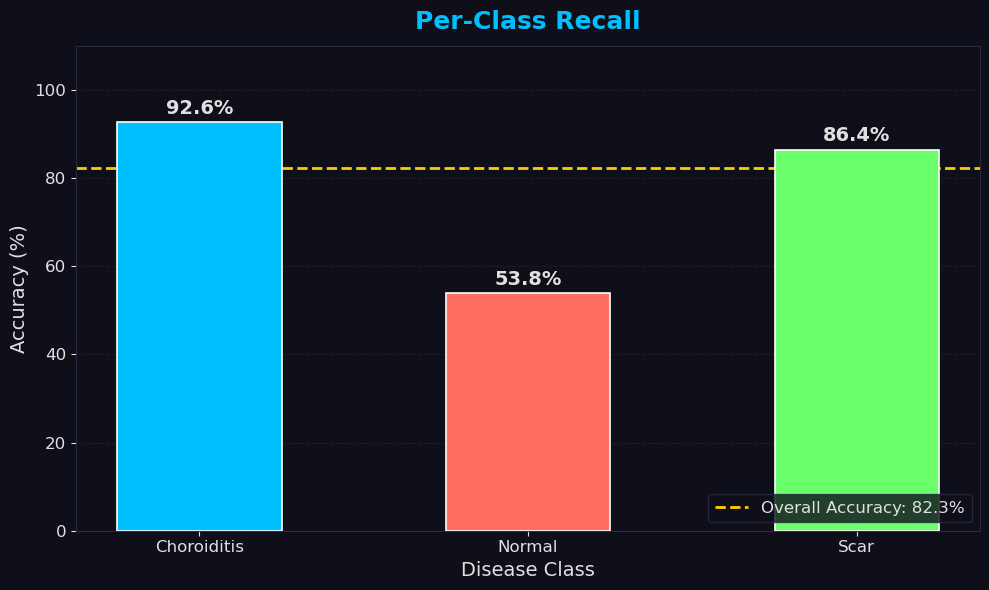


✅ Per-class accuracy chart saved to per_class_accuracy.png


In [10]:
# ==========================================
# PER-CLASS ACCURACY BAR CHART
# ==========================================

per_class_acc = cm.diagonal() / cm.sum(axis=1) * 100

fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

bar_colors = ['#00bfff', '#ff6f61', '#6bff6b']
bars = ax.bar(class_names, per_class_acc, color=bar_colors, edgecolor='white',
              linewidth=1.2, width=0.5, zorder=3)

# Add value labels on bars
for bar, acc in zip(bars, per_class_acc):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.0,
            f"{acc:.1f}%", ha='center', va='bottom',
            fontsize=14, fontweight='bold', color=TEXT_COLOR)

# Add overall accuracy line
ax.axhline(y=overall_acc, color='#ffcc00', linestyle='--', linewidth=2,
           label=f'Overall Accuracy: {overall_acc:.1f}%', zorder=2)

ax.set_ylim(0, 110)
ax.set_ylabel("Accuracy (%)", fontsize=14, color=TEXT_COLOR)
ax.set_xlabel("Disease Class", fontsize=14, color=TEXT_COLOR)
ax.set_title("Per-Class Recall", fontsize=18, fontweight='bold',
             color=ACCENT, pad=12)
ax.tick_params(colors=TEXT_COLOR, labelsize=12)
ax.legend(fontsize=12, loc='lower right', facecolor=BG_COLOR,
          edgecolor=GRID_COLOR, labelcolor=TEXT_COLOR)
ax.grid(axis='y', color=GRID_COLOR, linestyle='--', alpha=0.5, zorder=1)

for spine in ax.spines.values():
    spine.set_color(GRID_COLOR)

plt.tight_layout()
plt.savefig("per_class_accuracy.png", dpi=150, facecolor=BG_COLOR,
            bbox_inches='tight', pad_inches=0.3)
plt.show()

print("\n✅ Per-class accuracy chart saved to per_class_accuracy.png")

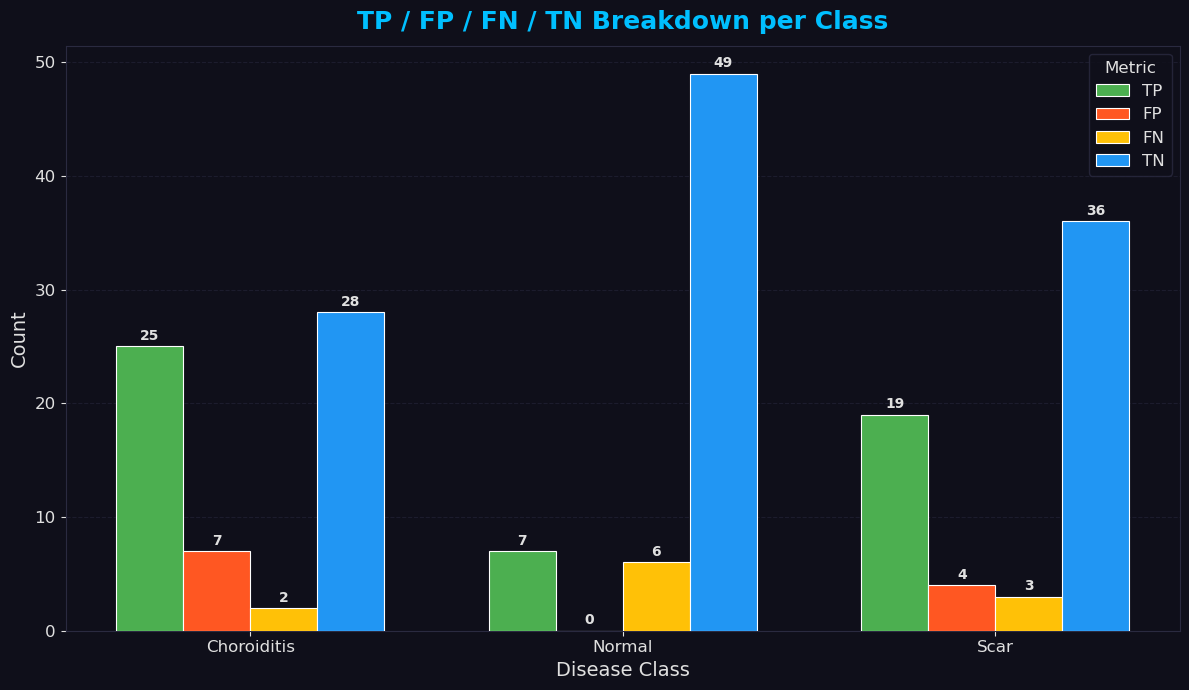


✅ TP/FP/FN/TN breakdown chart saved to tp_fp_fn_tn_breakdown.png


In [11]:
# ==========================================
# TP / FP / FN / TN GROUPED BAR CHART
# ==========================================

metrics_data = {}
for idx, cls in enumerate(class_names):
    tp = cm[idx, idx]
    fp = cm[:, idx].sum() - tp
    fn = cm[idx, :].sum() - tp
    tn = cm.sum() - tp - fp - fn
    metrics_data[cls] = {'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)}

metric_names = ['TP', 'FP', 'FN', 'TN']
metric_colors = {'TP': '#4CAF50', 'FP': '#FF5722', 'FN': '#FFC107', 'TN': '#2196F3'}

x = np.arange(len(class_names))
bar_width = 0.18

fig, ax = plt.subplots(figsize=(12, 7), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

for i, metric in enumerate(metric_names):
    values = [metrics_data[cls][metric] for cls in class_names]
    offset = (i - 1.5) * bar_width
    bars = ax.bar(x + offset, values, bar_width, label=metric,
                  color=metric_colors[metric], edgecolor='white',
                  linewidth=0.8, zorder=3)
    # Add value labels
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                str(val), ha='center', va='bottom',
                fontsize=10, fontweight='bold', color=TEXT_COLOR)

ax.set_xticks(x)
ax.set_xticklabels(class_names, fontsize=13)
ax.set_ylabel("Count", fontsize=14, color=TEXT_COLOR)
ax.set_xlabel("Disease Class", fontsize=14, color=TEXT_COLOR)
ax.set_title("TP / FP / FN / TN Breakdown per Class",
             fontsize=18, fontweight='bold', color=ACCENT, pad=12)
ax.tick_params(colors=TEXT_COLOR, labelsize=12)
ax.legend(fontsize=12, loc='upper right', facecolor=BG_COLOR,
          edgecolor=GRID_COLOR, labelcolor=TEXT_COLOR,
          title="Metric", title_fontsize=12)
# Style legend title
ax.get_legend().get_title().set_color(TEXT_COLOR)

ax.grid(axis='y', color=GRID_COLOR, linestyle='--', alpha=0.5, zorder=1)

for spine in ax.spines.values():
    spine.set_color(GRID_COLOR)

plt.tight_layout()
plt.savefig("tp_fp_fn_tn_breakdown.png", dpi=150, facecolor=BG_COLOR,
            bbox_inches='tight', pad_inches=0.3)
plt.show()

print("\n✅ TP/FP/FN/TN breakdown chart saved to tp_fp_fn_tn_breakdown.png")

In [12]:
# ==========================================
# SUMMARY
# ==========================================
print("=" * 60)
print("📊 EVALUATION SUMMARY")
print("=" * 60)
print(f"Model            : ResNet-18")
print(f"Number of classes : {num_classes}")
print(f"Classes           : {class_names}")
print(f"Total images      : {len(all_labels)}")
print(f"Overall Accuracy  : {overall_acc:.2f}%")
print()
for idx, cls in enumerate(class_names):
    acc = cm[idx, idx] / cm[idx, :].sum() * 100
    print(f"  {cls:<15}: {acc:.1f}% ({cm[idx, idx]}/{cm[idx, :].sum()})")
print("=" * 60)

📊 EVALUATION SUMMARY
Model            : ResNet-18
Number of classes : 3
Classes           : ['Choroiditis', 'Normal', 'Scar']
Total images      : 62
Overall Accuracy  : 82.26%

  Choroiditis    : 92.6% (25/27)
  Normal         : 53.8% (7/13)
  Scar           : 86.4% (19/22)
